# manasight 01: Data

**Question for the whole project:** can a model tell a Magic card's **color** and **type** from its artwork alone,
and does it do so from the *palette* (red = fire tones) or from the *content* (goblins, swamps, angels)?

**Goal of this notebook:** build the dataset. One row and one image file per unique illustration, with labels and splits.

**Builds on:** the [MTG Art Classifier](https://huggingface.co/BuildITSystems/mtg-art-cnn) by Nathan King (October 2026).
We follow the same test sets and label rules so results are comparable.

Sections:
1. Download the card list
2. Keep real cards only
3. One row per illustration
4. Labels
5. Test split: 10 held-out sets
6. Lands
7. Two extra splits
8. Save the table
9. Download the art
10. Checks
11. Summary

In [16]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import (BULK_FILE, CARDS_CSV, ART_DIR, COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, HELD_OUT_SETS,
                            download_bulk_file, read_printings, one_row_per_illustration, add_splits,
                            download_art, load_cards)

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]   # paintings: jpeg keeps the notebook small

## 1. Download the card list

[Scryfall](https://scryfall.com/docs/api/bulk-data) publishes a daily file with every card. We use **Default Cards**:
every English printing (about 80 MB compressed). We need all printings, not just one per picture,
because the split in step 5 has to know every set a card was printed in.

In [17]:
download_bulk_file()

already downloaded: default_cards.jsonl.gz


## 2. Keep real cards only

Rules (in `is_real_card`): English, printed on paper, normal size, has an image. Not a token, emblem, art card,
joke set or test print. Two-sided cards: we use the **front** picture only.

In [18]:
printings = read_printings()
print(f"printings kept: {len(printings):,}")
print(f"different cards: {printings.oracle_id.nunique():,}")
print(f"different illustrations: {printings.illustration_id.nunique():,}")
printings[["name", "set", "released_at", "artist", "type_line", "color_identity"]].sample(5, random_state=0)

printings kept: 96,326
different cards: 32,737
different illustrations: 48,349


,name,set,released_at,artist,type_line,color_identity
12687,Island,bfz,2015-10-02,Adam Paquette,Basic Land — Island,U
1466,Jace's Ruse,war,2019-05-03,Clint Cearley,Sorcery,U
94151,Fetid Pools,msc,2026-06-26,Jonas De Ro,Land — Island Swamp,BU
42064,Myconid Spore Tender,clb,2022-06-10,Brian Valeza,Creature — Fungus,G
24951,Ochre Jelly,pafr,2021-07-23,Daarken,Creature — Ooze,G


**Finding:** there are about twice as many printings as pictures. The same picture is reprinted a lot.

## 3. One row per illustration

Scryfall gives every painting an `illustration_id`. If we kept every printing, the same picture could land in both
train and test. We keep **one printing per picture**: the one in a held-out set if there is one, otherwise the oldest.

In [19]:
cards = one_row_per_illustration(printings)
print(f"illustrations: {len(cards):,}")

# how often is one picture printed?
times_printed = printings.illustration_id.value_counts()
print(f"printed once: {(times_printed == 1).mean():.0%}, most reprinted picture: {times_printed.max()} times")

illustrations: 48,349
printed once: 55%, most reprinted picture: 41 times


## 4. Labels

**Color (7 classes):** from the card's *color identity*. One color = that color, no color = Colorless, two or more = Multicolor.

**Type (7 classes):** a card can have several types. The first match wins, in this order:
Creature > Planeswalker > Land > Artifact > Enchantment > Instant > Sorcery.
So an "Artifact Creature" counts as Creature.

In [20]:
no_type = cards[cards.type.isna()]
print(f"cards with none of the 7 types (dropped): {len(no_type)}")
print(no_type.type_line.str.split("—").str[0].str.strip().value_counts().to_string())

cards = cards[cards.type.notna()].reset_index(drop=True)
print(f"\nillustrations left: {len(cards):,}")

cards with none of the 7 types (dropped): 71
type_line
Battle          36
Conspiracy      27
Stickers         5
Card             2
Summon Licid     1

illustrations left: 48,278


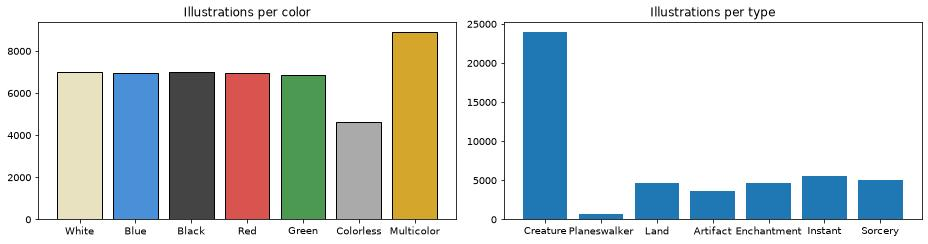

color
W             0.145
U             0.144
B             0.145
R             0.145
G             0.142
Colorless     0.095
Multicolor    0.185

type
Creature        0.497
Planeswalker    0.014
Land            0.097
Artifact        0.076
Enchantment     0.096
Instant         0.114
Sorcery         0.105


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

color_counts = cards.color.value_counts()[COLOR_CLASSES]
bar_colors = ["#e8e2c0", "#4a90d9", "#444444", "#d9534f", "#4c9a52", "#aaaaaa", "#d4a72c"]
axes[0].bar([COLOR_NAMES[c] for c in COLOR_CLASSES], color_counts.values, color=bar_colors, edgecolor="black")
axes[0].set_title("Illustrations per color")

type_counts = cards.type.value_counts()[TYPE_CLASSES]
axes[1].bar(TYPE_CLASSES, type_counts.values)
axes[1].set_title("Illustrations per type")
plt.tight_layout()
plt.show()

print((color_counts / len(cards)).round(3).to_string())
print()
print((type_counts / len(cards)).round(3).to_string())

**Finding:** the five colors are close to balanced; Multicolor is the biggest class and Colorless the smallest.
Type is very unbalanced: about half of all pictures are creatures, and planeswalkers are rare.

**Decision:** accuracy alone would flatter a model that always says "Creature". We report **macro-F1** next to accuracy
(the same metrics as the reference project).

## 5. Test split: 10 held-out sets

The test set is 10 whole sets, 2 per card-frame era, the same sets as the reference project. A whole set is a harder and
fairer test than random cards: the model has never seen that set's world or art direction.

One more rule we follow: *every other printing of those cards is removed from training*.
Many cards have several different paintings. If one painting of Lightning Bolt is in the test set and another is in
training, the model has seen the answer for that card.

There is more than one way to apply that rule, and basic lands (Plains, Island, Swamp, Mountain, Forest) need a
decision too: they are in almost every set and have hundreds of paintings each. We try the options and keep the one
whose counts match the reference split.

In [22]:
reference = {"train": 36325, "val": 4953, "test": 3401}

rows = [dict(rule="reference split", **reference)]
for remove_by in ("card", "picture"):
    for drop_basics in (True, False):
        s = add_splits(cards, printings, remove_by=remove_by, drop_basics=drop_basics).split.value_counts()
        rows.append({"rule": f"remove by {remove_by}, " + ("no basic lands" if drop_basics else "with basic lands"),
                     "train": s["train"], "val": s["val"], "test": s["test"]})
compare = pd.DataFrame(rows).set_index("rule")
compare["total"] = compare.sum(axis=1)
compare

,train,val,test,total
rule,,,,
reference split,36325,4953,3401,44679
"remove by card, no basic lands",36222,4935,3392,44549
"remove by card, with basic lands",36232,4936,3572,44740
"remove by picture, no basic lands",37809,5147,3392,46348
"remove by picture, with basic lands",39345,5361,3572,48278


**Finding:** "remove by card, no basic lands" lands within 0.3% of all three reference counts. The other options are
off by thousands in train or by 170 in test. The small difference left is expected: Scryfall changes every day and
our filters were written independently.

**Decision:** the main split uses **remove by card, no basic lands**. Validation is 12% of the remaining cards
(the same share as the reference split), picked by card so two paintings of one card never sit on both sides, and with the same color mix as training.
The split is rebuilt from the published description, so it is close but not identical.

In [23]:
cards = add_splits(cards, printings, remove_by="card", drop_basics=True)
print(cards.split.value_counts().to_string())

test = cards[cards.split == "test"].copy()
test["year"] = test.released_at.str[:4]
per_set = test.groupby(["era", "set", "set_name", "year"]).size().to_frame("illustrations")
per_set

split
train      36222
val         4935
removed     3729
test        3392


illustrations
era   set set_name                   year               
1993  ice Ice Age                    1995            363
      leg Legends                    1994            310
1997  7ed Seventh Edition            2001            331
      inv Invasion                   2000            331
2003  lrw Lorwyn                     2007            281
      rtr Return to Ravnica          2012            249
2015  lci The Lost Caverns of Ixalan 2023            355
      neo Kamigawa: Neon Dynasty     2022            401
                                     2023              1
2024+ dft Aetherdrift                2025            371
      fra Reality Fracture           2026            399

In [24]:
# color mix per split (share of each split)
mix = pd.crosstab(cards.color, cards.split, normalize="columns").loc[COLOR_CLASSES, ["train", "val", "test"]]
mix.index = [COLOR_NAMES[c] for c in COLOR_CLASSES]
print(mix.round(3).to_string())
print()
print(pd.crosstab(cards.type, cards.split, normalize="columns").loc[TYPE_CLASSES, ["train", "val", "test"]].round(3).to_string())

split       train    val   test
White       0.143  0.143  0.144
Blue        0.140  0.140  0.143
Black       0.144  0.144  0.143
Red         0.142  0.142  0.145
Green       0.139  0.139  0.144
Colorless   0.101  0.101  0.079
Multicolor  0.193  0.193  0.202

split         train    val   test
type                             
Creature      0.532  0.508  0.499
Planeswalker  0.014  0.018  0.013
Land          0.057  0.058  0.055
Artifact      0.077  0.084  0.099
Enchantment   0.097  0.092  0.127
Instant       0.113  0.122  0.118
Sorcery       0.108  0.117  0.089


**Finding:** train and val have the same color mix (by design). The test sets are close to it: a little more
Multicolor (20% vs 19%) and a little less Colorless (8% vs 10%). The type mix is close too.
The split does not hand the model an easy or a strange test set.

## 6. Lands

Color identity gives lands a color too: a land that makes green mana is Green. That keeps the labels the same as the reference
project, so lands stay in. But lands are a special case (landscapes, no creature in the picture), so the table keeps two
flags, `is_land` and `is_basic`, and later notebooks also report scores **without lands**.

In [25]:
lands = cards[cards.is_land & (cards.split != "removed")]
print(f"lands in the main split: {len(lands):,} ({len(lands) / (cards.split != 'removed').sum():.1%})")
print(f"basic lands (left out of the main split): {cards.is_basic.sum():,}")
print()
print("color of the lands in the main split:")
print(lands.color.map(COLOR_NAMES).value_counts().to_string())

lands in the main split: 2,558 (5.7%)
basic lands (left out of the main split): 1,930

color of the lands in the main split:
color
Multicolor    1238
Colorless      886
Black          101
Red             87
Blue            87
White           81
Green           78


**Finding:** most non-basic lands are Colorless or Multicolor by identity, not one clean color. A forest painting can
belong to a Colorless or a Multicolor land. For lands the label comes from the rules text, which the art may not show.

## 7. Two extra splits

For later questions we add two more split columns now, so every notebook uses the same ones:

- `split_random`: random 80/10/10 by card. Ignores sets. The "easy" split.
- `split_artist`: 80/10/10 by artist. Every artist is in one split only. If scores drop here compared with
  `split_random`, the model was partly recognizing artists' styles.

Both include basic lands (filter with `is_basic` if needed).

In [26]:
print(pd.DataFrame({"split_random": cards.split_random.value_counts(),
                    "split_artist": cards.split_artist.value_counts()}).to_string())
print(f"\nartists: {cards.artist.nunique():,}")
print("artists per split:", cards.groupby("split_artist").artist.nunique().to_dict())
by_artist = cards.artist.value_counts()
print(f"biggest artist: {by_artist.index[0]} with {by_artist.iloc[0]} illustrations; half of the artists have {int(by_artist.median())} or fewer")

       split_random  split_artist
train         38984         38928
test           4762          5175
val            4532          4175

artists: 2,329
artists per split: {'test': 257, 'train': 1853, 'val': 219}
biggest artist: Kev Walker with 477 illustrations; half of the artists have 5 or fewer


## 8. Save the table

`data/cards.csv` is the dataset: one row per illustration with labels, splits and the image address.
It is committed to the repo, so the dataset stays fixed even though Scryfall's file changes daily.

In [27]:
cards.drop(columns=["held_out"]).to_csv(CARDS_CSV, index=False)
print(f"saved {CARDS_CSV.name}: {len(cards):,} rows, {CARDS_CSV.stat().st_size / 1e6:.0f} MB")

saved cards.csv: 48,278 rows, 15 MB


## 9. Download the art

Scryfall's `art_crop` image is the painting only, without the card frame or text.
Each one is shrunk so its short side is 224 px (the size pretrained models expect) and saved as a JPEG.

This takes a while the first time (about 45 minutes). It is safe to stop and run again: files already on disk are skipped.

In [28]:
cards = load_cards()
failed = download_art(cards)
failed[:5]

48,278 of 48,278 already on disk
downloading 0


0it [00:00, ?it/s]

done, 0 failed


[]

## 10. Checks

In [29]:
on_disk = pd.Series([Path(p).exists() for p in cards.path], index=cards.index)
print(f"images on disk: {on_disk.sum():,} of {len(cards):,}")

# open every image fully: catches broken files and collects the sizes
sizes = []
broken = []
total_bytes = 0
for p in cards.path[on_disk]:
    total_bytes += Path(p).stat().st_size
    try:
        with Image.open(p) as im:
            im.load()
            sizes.append(im.size)
    except Exception:
        broken.append(p)

print(f"disk space: {total_bytes / 1e9:.2f} GB, {total_bytes / on_disk.sum() / 1e3:.0f} KB per image")
print(f"broken files: {len(broken)}")

sizes = pd.DataFrame(sizes, columns=["width", "height"])
print("\nimage sizes:")
print(sizes.describe().loc[["min", "50%", "max"]].to_string())

images on disk: 48,278 of 48,278
disk space: 0.90 GB, 19 KB per image
broken files: 0

image sizes:
     width  height
min  224.0   224.0
50%  307.0   224.0
max  993.0   540.0


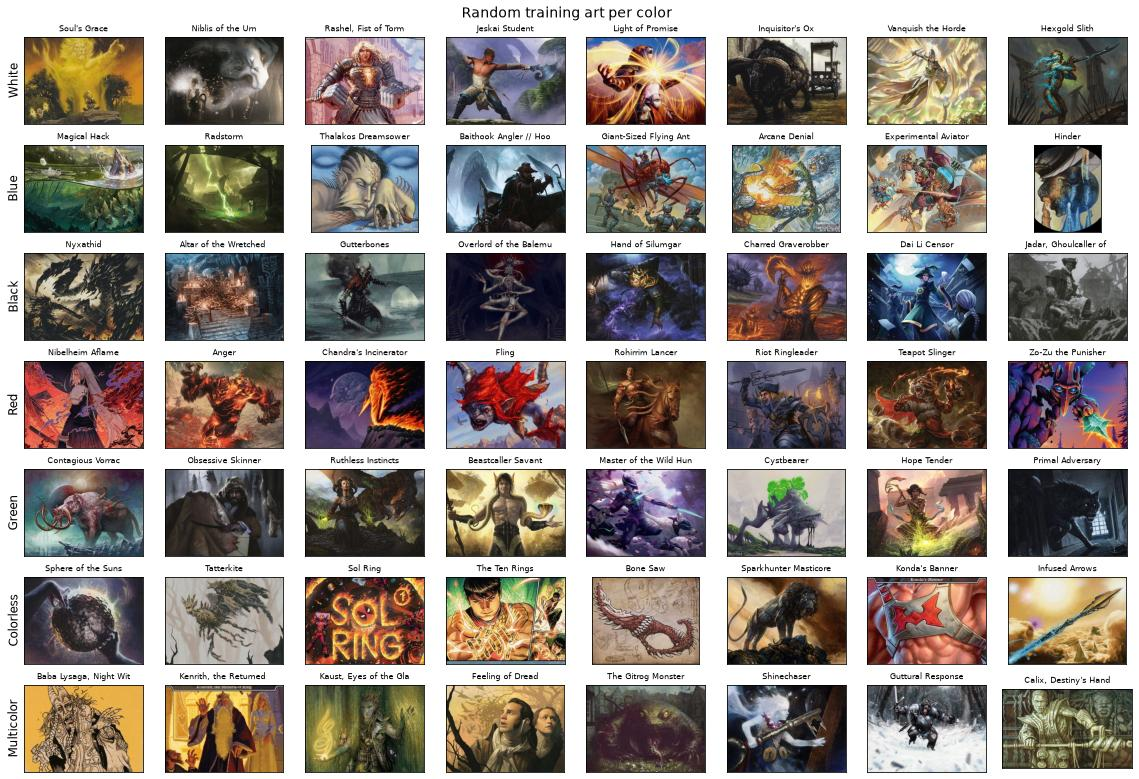

In [30]:
# 8 random paintings per color from the training split
train = cards[(cards.split == "train") & on_disk]

fig, axes = plt.subplots(7, 8, figsize=(16, 11))
for row, color in enumerate(COLOR_CLASSES):
    picks = train[train.color == color].sample(8, random_state=1)
    for ax, card in zip(axes[row], picks.itertuples()):
        ax.imshow(Image.open(card.path))
        ax.set_title(card.name[:22], fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(COLOR_NAMES[color], fontsize=12)
plt.suptitle("Random training art per color", fontsize=14)
plt.tight_layout()
plt.show()

**Finding:** some rows lean toward a palette: red art is often fire and lava tones, white is often gold and light,
black is mostly dark. But plenty of pictures break it: blue cards painted in greens and yellows, green cards in purples
and greys. Colorless and Multicolor have no palette of their own. Content shows up too (angels and soldiers, beasts, undead).
Neither cue is clean by eye. Which one a model actually uses is the question for the next notebooks.

Also visible: a few pictures are not classic paintings (comic-style art, art with lettering in it). Those come from
special printings and are worth a closer look in the EDA.

## 11. Summary

- Source: Scryfall Default Cards. English paper cards, no tokens, joke sets or test prints. Front picture only.
- One row per illustration. 7 color classes (color identity) and 7 type classes (first match wins).
- **Main split** (`split`): test = 10 held-out sets (2 per frame era); other paintings of test cards and basic lands
  removed; val = 12% of the remaining cards. Counts are within 0.3% of the reference split.
- Extra splits: `split_random` and `split_artist`. Flags: `is_land`, `is_basic`. Column `era` for the test sets.
- Images: `data/art/<illustration_id>.jpg`, short side 224 px.
- Type is unbalanced (half creatures) -> report macro-F1 next to accuracy.
- The test sets have more Multicolor cards than training.

**Next:** 02 looks closer at the pictures (EDA) and sets the simplest baselines: chance and "always guess the biggest class".

Card data and images: [Scryfall](https://scryfall.com). Card art is © Wizards of the Coast and the artists (the `artist` column credits each one).